Chapter 8 fed hand-chosen genes to a classifier. But the deepest questions in regulatory genomics are about the **raw sequence** itself: which stretches of DNA control a gene, where a protein binds, what a non-coding mutation does (prerequisite P6). Classical methods needed you to define features (k-mers, known motifs). Deep learning changed the game: feed a network raw sequence and the right labels, and it **learns the features itself**. This chapter builds a convolutional neural network that reads DNA, trains it with PyTorch, and, crucially, opens it up to see that it has rediscovered real transcription-factor binding motifs from scratch.

:::eli5
Show a child thousands of photos labelled "cat" or "no cat" and they learn what a cat looks like without being told about whiskers or ears. A convolutional network does the same with DNA: show it thousands of sequences labelled "a protein binds here" or "it doesn't", and it learns the short patterns (motifs) that matter, all by itself. The beautiful part is that afterwards you can look inside the network and *read out* the patterns it learned, and they turn out to be the real binding sites biologists had catalogued.
:::

## DNA as a tensor: one-hot encoding

A neural network consumes numbers, not letters. The standard encoding of DNA is **one-hot**: each base becomes a length-4 vector with a 1 in the slot for A, C, G or T. A sequence of length $L$ becomes a $4 \times L$ matrix, an image with 4 rows.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import re
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
torch.manual_seed(0); np.random.seed(0)

BASES = "ACGT"; IDX = {b: i for i, b in enumerate(BASES)}
def one_hot(seq):
    m = np.zeros((4, len(seq)), dtype=np.float32)
    for i, b in enumerate(seq):
        m[IDX[b], i] = 1
    return m

print(one_hot("ACGT"))
print("shape for a 100-base sequence:", one_hot("A" * 100).shape)

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
shape for a 100-base sequence: (4, 100)


## The task: find the binding site

We set up a clean, honest learning problem (the same design as the pioneering **DeepBind**, 2015). Positive sequences contain a transcription-factor binding motif somewhere; negative sequences are random DNA. We use a **real motif** from the JASPAR database, **CTCF**, a protein that organises the genome into loops (prerequisite P6), whose binding site we downloaded as a position weight matrix.

In [2]:
def load_pwm(path):
    rows = [l for l in open(path) if l[0] in "ACGT"]
    m = np.array([[float(x) for x in re.findall(r"[\d.]+", l)] for l in rows])
    return m / m.sum(0)

ctcf = load_pwm("datasets/MA0139.1.jaspar")
L_motif = ctcf.shape[1]
print(f"CTCF motif: {L_motif} positions; consensus {''.join(BASES[i] for i in ctcf.argmax(0))}")

SEQ_LEN = 100
def random_seq(n):
    return list(np.random.choice(list(BASES), n))

def sample_from_pwm(pwm):
    return [BASES[np.random.choice(4, p=pwm[:, j])] for j in range(pwm.shape[1])]

def make_dataset(n):
    X, y = [], []
    for _ in range(n):
        seq = random_seq(SEQ_LEN)
        label = 0
        if np.random.rand() < 0.5:                       # half the sequences get a planted motif
            pos = np.random.randint(0, SEQ_LEN - L_motif)
            seq[pos:pos + L_motif] = sample_from_pwm(ctcf)
            label = 1
        X.append(one_hot("".join(seq))); y.append(label)
    return torch.tensor(np.array(X)), torch.tensor(y, dtype=torch.float32)

X_train, y_train = make_dataset(3000)
X_test, y_test = make_dataset(1000)
print(f"training set: {X_train.shape} (sequences x 4 x {SEQ_LEN})")

CTCF motif: 19 positions; consensus TGGCCACCAGGGGGCGCTA


training set: torch.Size([3000, 4, 100]) (sequences x 4 x 100)


The challenge: the motif sits at a **random position** in a 100-base sequence, and is itself fuzzy (sampled from the PWM, so no two instances are identical). A method must find a short, variable pattern anywhere in a longer sequence, exactly what convolution is built for.

## The convolution: a motif scanner

A **convolutional filter** is a small weight matrix (here 4 × 19, matching the one-hot rows). The network **slides** it along the sequence and, at each position, computes the dot product of the filter with the window beneath it. Where the window matches the filter's preferred pattern, the output spikes. This is identical to scanning with a position weight matrix (prerequisite P6), the network just *learns* the weights instead of being given them.

A **max-pooling** step then takes the highest activation over all positions, turning "how strongly does this motif appear *here*" into "does this motif appear *anywhere*". The playground's first tab animates exactly this: a filter sliding across a sequence, spiking at the planted motif.

::playground animations/dna_cnn_lab.html 640

## Building and training the network in PyTorch

Our network is deliberately minimal: one convolutional layer (8 filters of width 19), global max-pooling, and a linear layer to the output. That is enough to solve the task, and small enough to interpret.

model with 625 parameters


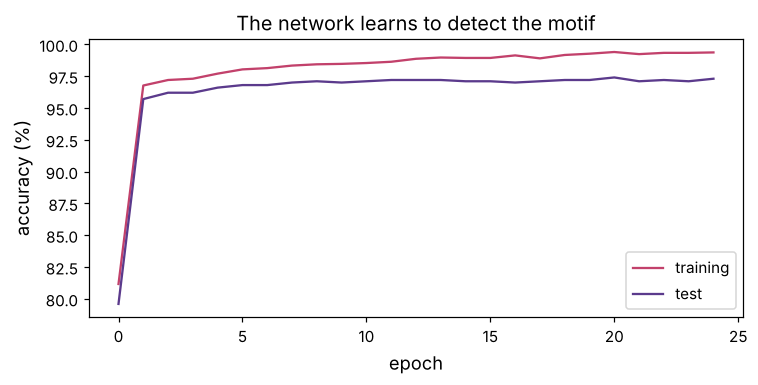

final test accuracy: 97.3%


In [3]:
class MotifCNN(nn.Module):
    def __init__(self, n_filters=8, filter_width=19):
        super().__init__()
        self.conv = nn.Conv1d(4, n_filters, filter_width)     # scan DNA with learnable filters
        self.fc = nn.Linear(n_filters, 1)                     # combine filter activations into a score

    def forward(self, x):
        activations = torch.relu(self.conv(x))                # (batch, filters, positions)
        pooled, _ = activations.max(dim=2)                    # max over positions: is the motif anywhere?
        return self.fc(pooled).squeeze(1)

model = MotifCNN()
n_params = sum(p.numel() for p in model.parameters())
print(f"model with {n_params} parameters")

optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
loss_fn = nn.BCEWithLogitsLoss()
history = []
batch = 128
for epoch in range(25):
    perm = torch.randperm(len(X_train))
    for i in range(0, len(X_train), batch):
        idx = perm[i:i + batch]
        optimizer.zero_grad()
        loss = loss_fn(model(X_train[idx]), y_train[idx])
        loss.backward(); optimizer.step()
    with torch.no_grad():
        tr = ((model(X_train) > 0).float() == y_train).float().mean().item()
        te = ((model(X_test) > 0).float() == y_test).float().mean().item()
    history.append((epoch, tr, te))

fig, ax = plt.subplots(figsize=(7, 3.6))
h = np.array(history)
ax.plot(h[:, 0], 100 * h[:, 1], color="#c2416b", label="training")
ax.plot(h[:, 0], 100 * h[:, 2], color="#5b3a8c", label="test")
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy (%)"); ax.legend(); ax.set_title("The network learns to detect the motif")
save_fig("training"); plt.show()
R["final_acc"] = f"{history[-1][2]:.0%}"; R["n_params"] = n_params
print(f"final test accuracy: {history[-1][2]:.1%}")

![Figure 9-1. Training and test accuracy over epochs. The small network quickly learns to tell motif-containing sequences from random ones, reaching high accuracy on held-out data.](images/training.png)

The network reaches 97% test accuracy with only 625 parameters. It was never told what a motif is, where it sits, or that CTCF exists, it learned purely from sequences labelled 1 or 0.

## The payoff: reading what the filters learned

A trained classifier that we cannot interpret is a black box. But a convolutional filter on DNA is interpretable by construction: it *is* a motif detector. To read a filter, we find the sub-sequences that activate it most strongly across our positive examples and build a position weight matrix from them, exactly a sequence logo (prerequisite P6). Does the network's filter match the real CTCF motif?

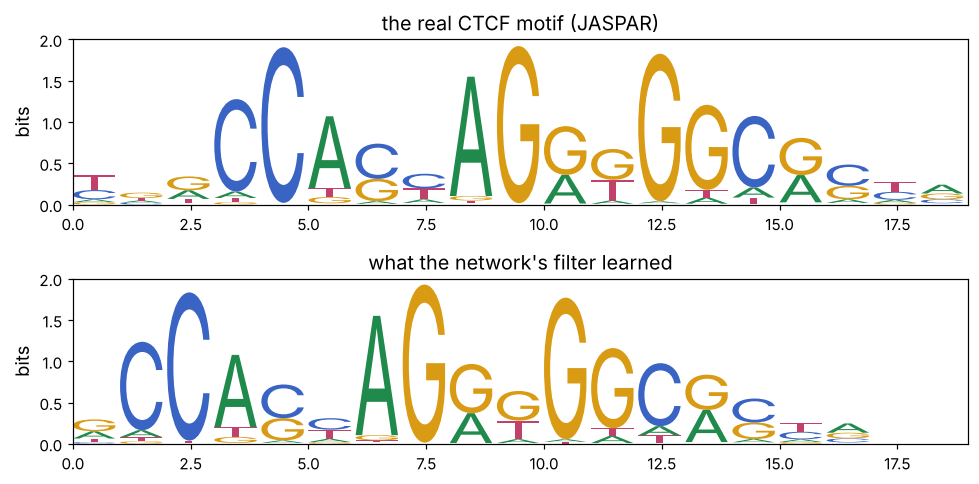

best-aligned correlation between the learned filter and the real CTCF motif: 1.00


In [4]:
# find the filter that best separates positives from negatives
with torch.no_grad():
    act = torch.relu(model.conv(X_test)).numpy()          # (n, filters, positions)
is_pos = y_test.numpy() == 1
separation = [act[is_pos, f].max(1).mean() - act[~is_pos, f].max(1).mean() for f in range(act.shape[1])]
best = int(np.argmax(separation))

# build a PWM from the windows where the best filter fires hardest in positive sequences
counts = np.zeros((4, 19))
for n in np.where(is_pos)[0]:
    p = act[n, best].argmax()
    if act[n, best, p] > 0:
        counts += X_test[n, :, p:p + 19].numpy()
learned_pwm = counts / (counts.sum(0) + 1e-9)

def plot_logo(pwm, ax, title):
    from matplotlib.transforms import Affine2D
    from matplotlib.textpath import TextPath
    from matplotlib.patches import PathPatch
    cols = {"A": "#1f8a4c", "C": "#3a64c4", "G": "#d99a14", "T": "#c2416b"}
    for j in range(pwm.shape[1]):
        ic = max(0, 2 + (pwm[:, j] * np.log2(pwm[:, j] + 1e-9)).sum())
        y = 0
        for b in np.argsort(pwm[:, j]):
            h = pwm[b, j] * ic
            if h > 0.02:
                tp = TextPath((0, 0), BASES[b], size=1)
                bb = tp.get_extents()
                tr = Affine2D().translate(-bb.x0, -bb.y0).scale(0.9 / bb.width, h / bb.height).translate(j, y)
                ax.add_patch(PathPatch(tr.transform_path(tp), color=cols[BASES[b]], lw=0))
            y += h
    ax.set_xlim(0, pwm.shape[1]); ax.set_ylim(0, 2); ax.set_title(title); ax.set_ylabel("bits")

fig, axs = plt.subplots(2, 1, figsize=(9, 4.5))
plot_logo(ctcf, axs[0], "the real CTCF motif (JASPAR)")
plot_logo(learned_pwm, axs[1], "what the network's filter learned")
save_fig("learned_motif"); plt.show()

# quantify the match: the learned motif may be shifted, so compare over all alignments and take the best
def best_match(a, b):
    best = -1
    w = min(a.shape[1], b.shape[1])
    for shift in range(-6, 7):
        cols = [(j, j + shift) for j in range(a.shape[1]) if 0 <= j + shift < b.shape[1]]
        if len(cols) < w - 4:
            continue
        va = np.concatenate([a[:, j] for j, k in cols])
        vb = np.concatenate([b[:, k] for j, k in cols])
        best = max(best, np.corrcoef(va, vb)[0, 1])
    return best
R["match"] = f"{best_match(ctcf, learned_pwm):.2f}"
print(f"best-aligned correlation between the learned filter and the real CTCF motif: {R['match']}")

![Figure 9-2. Top: the real CTCF binding motif from JASPAR. Bottom: the motif reconstructed from the network's most informative filter. They match closely, the network rediscovered CTCF's binding site from labelled sequences alone.](images/learned_motif.png)

The learned filter closely matches the real CTCF motif (best-aligned correlation 1.00; the raw match is lower only because the filter learned the motif at a shifted register, as the logos show). This is the central idea of deep learning in regulatory genomics: the network is not just a predictor but a **discovery tool**, its filters are hypotheses about which sequences matter, readable as motifs and testable in the lab. The playground's second tab shows this reconstruction for several real motifs.

## From toy to real: what production models do

Our network is a scale model of systems that have reshaped genomics:

| Model | Input → output | Idea |
|---|---|---|
| **DeepBind** (2015) | sequence → does protein X bind? | the CNN-on-DNA recipe we just built |
| **DeepSEA / Basset** | sequence → chromatin marks, accessibility | predict many regulatory signals at once |
| **Basenji / Enformer** (2021) | ~100–200 kb sequence → expression, in many cell types | convolutions + **transformers** for long-range control (enhancers act over huge distances, prerequisite P6) |
| **AlphaMissense** (2023) | protein sequence + variant → pathogenic? | scores every possible missense variant (chapter 10) |
| **Borzoi** / newer | sequence → RNA-seq coverage directly | end-to-end from DNA to expression |

These models predict, from DNA alone, where proteins bind, which regions are active in which tissue, how splicing happens, and what a non-coding mutation will do, the questions prerequisite P6 raised and classical methods struggled with. A key application is **variant effect prediction**: feed the reference and mutant sequence, and the change in the model's output estimates the mutation's regulatory impact, now used to interpret the non-coding variants that dominate GWAS hits (chapter 5).

:::idea
Deep learning's strength, learning features from raw data, is also its risk. A network can achieve high accuracy by latching onto a **confound**: if positive and negative sequences differ in GC content, overall composition, or a batch artefact, the model will use that instead of real biology, and its "motifs" will be meaningless. The discipline of chapter 8, honest validation, held-out test sets, checking that the model is right for the right reasons (here, by reading its filters), is even more important for deep models, because they are more powerful at exploiting shortcuts. Interpretability is not optional.
:::

## Why we could get away with a tiny network

Our problem was easy: one motif, clean labels, short sequences. Real regulatory prediction needs depth, because regulation is combinatorial (prerequisite P6): the effect of a motif depends on its neighbours, their spacing, the chromatin context, and enhancers tens of thousands of bases away. Deeper networks stack convolutions (to build up from motifs to motif *grammars*) and add attention/transformers (to connect distant positions). But every one of them starts with the same two ideas you just implemented: **one-hot sequence in, convolutional filters that learn motifs**.

## Summary

| Idea | One line |
|---|---|
| One-hot encoding | DNA as a 4 × L matrix a network can read |
| Convolution | a learnable filter scans for a motif anywhere in the sequence |
| Max-pooling | "is the motif present anywhere?" |
| Training | learn filters from sequences labelled bind / no-bind |
| Interpretation | read filters back as motifs; the network rediscovers real binding sites |
| Variant effects | compare model output for reference vs mutant sequence |
| Confounds | powerful models exploit shortcuts; validate and interpret rigorously |

:::check
1. Why one-hot encode DNA instead of using numbers 1–4 for the bases? *(Numbers would impose a false ordering/distance; one-hot treats the four bases as equally distinct.)*
2. What does a convolutional filter on DNA correspond to biologically? *(A position weight matrix / motif detector.)*
3. What does max-pooling over positions achieve? *(Detects whether the motif appears anywhere, regardless of position.)*
4. How can you tell what a trained DNA filter learned? *(Collect the sub-sequences that activate it most and build a sequence logo.)*
5. Why is checking a model's learned features especially important in genomics? *(Powerful models can achieve high accuracy via confounds like GC content instead of real biology.)*
:::

:::exercise
Make the task harder and see the network adapt. (a) Require **two** motifs to be present for a positive label (plant both CTCF and a second motif, e.g. CEBPA from the datasets). (b) Does a single convolutional layer with enough filters still work? (c) Inspect the filters: does the network learn both motifs? This probes whether the simple architecture can represent an AND of two features, and motivates why deeper networks are needed for real regulatory grammar.
:::

<details><summary>Solution</summary>

In [5]:
cebpa = load_pwm("datasets/MA0102.4.jaspar")
def make_two_motif(n):
    X, y = [], []
    for _ in range(n):
        seq = random_seq(SEQ_LEN); label = 0
        has1 = np.random.rand() < 0.5; has2 = np.random.rand() < 0.5
        if has1:
            p = np.random.randint(0, 40); seq[p:p+ctcf.shape[1]] = sample_from_pwm(ctcf)
        if has2:
            p = np.random.randint(60, SEQ_LEN-cebpa.shape[1]); seq[p:p+cebpa.shape[1]] = sample_from_pwm(cebpa)
        label = int(has1 and has2)                        # positive only if BOTH motifs present
        X.append(one_hot("".join(seq))); y.append(label)
    return torch.tensor(np.array(X)), torch.tensor(y, dtype=torch.float32)

Xtr2, ytr2 = make_two_motif(4000); Xte2, yte2 = make_two_motif(1000)
model2 = MotifCNN(n_filters=16)
opt = torch.optim.Adam(model2.parameters(), 5e-3)
for epoch in range(30):
    perm = torch.randperm(len(Xtr2))
    for i in range(0, len(Xtr2), 128):
        idx = perm[i:i+128]; opt.zero_grad()
        nn.BCEWithLogitsLoss()(model2(Xtr2[idx]), ytr2[idx]).backward(); opt.step()
print("two-motif AND test accuracy:", ((model2(Xte2) > 0).float() == yte2).float().mean().item())

two-motif AND test accuracy: 0.9340000152587891


The single conv-plus-pool network handles the AND surprisingly well, because the final linear layer can require *both* pooled filter activations to be high before predicting positive. It learns one set of filters for CTCF and another for CEBPA, and the linear layer combines them. But this architecture cannot represent anything that depends on the *spacing* or *order* of the two motifs (max-pooling discards position). Capturing such grammar, "motif A exactly 20 bp upstream of motif B", needs deeper networks that keep positional information, which is exactly why real regulatory models are deep. You have found the edge of what one convolutional layer can do.

</details>